## 步骤 1：定位项目，加载依赖与配置

项目根目录包含 `configs/`、`src/`、`scripts/`、`tests/`。下面兼容从根目录或子目录启动的情况。固定随机种子便于复现；相同批次、相同输入和相同种子应得到一致结果。

`configs/default.yaml` 是实验的唯一主要配置来源。模型不直接接受字符串，而接受**整数词 ID 序列**或**稀疏词频矩阵**，以明确共享词汇表和防止数据泄漏。

In [22]:
from pathlib import Path
import sys, json, subprocess
import numpy as np
import pandas as pd
import yaml
from scipy import sparse
from IPython.display import display, Markdown, Image
from threadpoolctl import threadpool_limits

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "configs/default.yaml").exists() and (p / "src").exists()), None)
if ROOT is None:
    raise RuntimeError("请从本项目目录或其子目录启动 Notebook")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

config = yaml.safe_load((ROOT / "configs/default.yaml").read_text(encoding="utf-8"))
cfg = config["experiment"]
SEED = cfg["seeds"][0]
print("项目目录：", ROOT)
print("Python：", sys.executable)
display(pd.DataFrame({"配置项": list(cfg), "取值": [str(v) for v in cfg.values()]}))

项目目录： d:\项目文件夹\作者信息主题建模
Python： d:\Softwares\Anaconda\envs\test1\python.exe


,配置项,取值
0,seeds,"[11, 29, 47]"
1,n_topics,10
2,lambda_author,10.0
3,lambda_grid,"[1, 5, 10, 20, 50, 100]"
4,topic_grid,"[5, 10, 15, 20, 30]"
5,documents_per_author_grid,"[4, 12, 32]"
6,gamma,0.5
7,beta,0.01
8,n_iter,240
9,burn_in,120


## 步骤 2：先理解 LDA 与 AP-LDA 的差别

LDA 假设每篇文档的主题比例 $\theta_d$ 独立来自同一个对称先验：

$$\theta_d\sim\operatorname{Dirichlet}(\alpha\mathbf1_K).$$

AP-LDA 为每位作者增加一个**需要从文本推断的随机偏好向量**：

$$\pi_a\sim\operatorname{Dirichlet}(\gamma\mathbf1_K),\qquad
\theta_d\mid\pi_{a(d)}\sim\operatorname{Dirichlet}(\lambda\pi_{a(d)}).$$

主题词分布仍为 $\phi_k\sim\operatorname{Dirichlet}(\beta\mathbf1_V)$；逐词先采主题，再按主题采词。

- $\pi_a$：作者长期倾向哪些主题；同作者的文档通过它共享信息。
- $\theta_d$：某一篇文档的主题比例；它可以偏离作者偏好。
- $\phi_k$：主题中哪些词更常见；所有文档共享同一套主题词分布。
- $\lambda$：Dirichlet **总浓度**。较大时文档更接近作者，较小时允许更多文档差异。

不是把作者名字当成文本中的词，也不是提前按词频人为指定 $\pi$。

理论上：

$$E[\theta_{dk}\mid\pi_a]=\pi_{ak},\quad
\operatorname{Var}(\theta_{dk}\mid\pi_a)=\frac{\pi_{ak}(1-\pi_{ak})}{\lambda+1}.$$

下面固定一位作者的偏好，通过实际抽样验证期望不变、方差随 $\lambda$ 增大而减小。这个小实验是数学性质验证，不是真实数据性能测试。

In [23]:
rng = np.random.default_rng(42)
author_preference = np.array([0.2, 0.3, 0.5])
moment_rows = []
for concentration in [1, 10, 100]:
    samples = rng.dirichlet(concentration * author_preference, size=30000)
    moment_rows.append({
        "λ": concentration,
        "抽样均值": np.round(samples.mean(0), 4),
        "理论均值": author_preference,
        "抽样方差": np.round(samples.var(0), 5),
        "理论方差": np.round(author_preference * (1-author_preference) / (concentration+1), 5),
    })
display(pd.DataFrame(moment_rows))

,λ,抽样均值,理论均值,抽样方差,理论方差
0,1,"[0.1986, 0.3005, 0.501]","[0.2, 0.3, 0.5]","[0.07893, 0.10528, 0.12545]","[0.08, 0.105, 0.125]"
1,10,"[0.1993, 0.3007, 0.5]","[0.2, 0.3, 0.5]","[0.01465, 0.01895, 0.02257]","[0.01455, 0.01909, 0.02273]"
2,100,"[0.2002, 0.2995, 0.5003]","[0.2, 0.3, 0.5]","[0.00158, 0.00208, 0.00248]","[0.00158, 0.00208, 0.00248]"


### 为什么不能直接套普通 LDA 的作者更新？

积分掉文档主题后，作者后验含有 $\Gamma(n_{dk}+\lambda\pi_{ak})/\Gamma(\lambda\pi_{ak})$，所以原空间里不是简单的 Dirichlet 共轭更新。

本项目用 **CRT 辅助桌数**处理它。利用升阶乘恒等式：

$$\frac{\Gamma(n+x)}{\Gamma(x)}=\sum_{t=0}^n |s(n,t)|x^t,$$

引入 $t_{dk}\sim\mathrm{CRT}(n_{dk},\lambda\pi_{a(d)k})$，才在扩充空间得到：

$$\pi_a\mid T,Z\sim\operatorname{Dirichlet}\left(\gamma\mathbf1+\sum_{d:a(d)=a}t_d\right).$$

一轮训练依次为：**更新逐词主题 $Z$ → 采桌数 $T$ → 采作者偏好 $\Pi$ → 丢弃旧桌数**。记录的是 MCMC 采样轨迹，不要求像优化损失那样单调。

完整联合分布、条件概率及更新顺序的依据见 [数学推导](reports/mathematical_model.md)。核心实现可直接阅读 `src/inference/inference.py` 与 `src/models/author_prior_lda.py`。

## 步骤 3：查看概率图模型

灰色节点表示已观测变量，白色圆表示潜变量。特别看：作者 π 与共享主题词 φ 分别在独立 plate 中；φ 不在文档 plate 里。已知作者索引 a(d) 选择相应的 π。

优先使用 Graphviz。当前环境若缺少系统 `dot`，会用 Matplotlib 输出同样的 PNG/SVG，并保留 DOT 源文件。

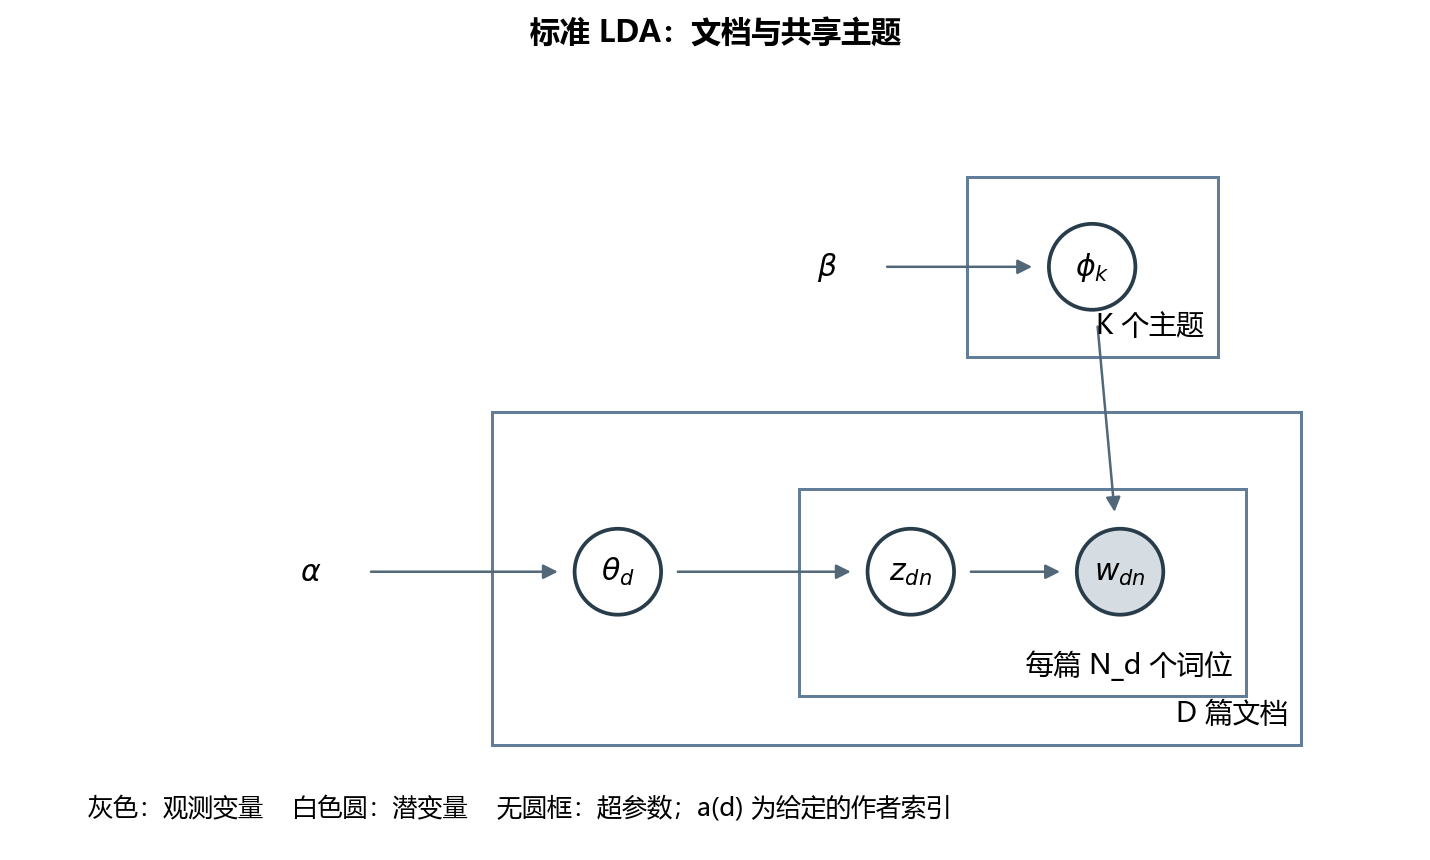

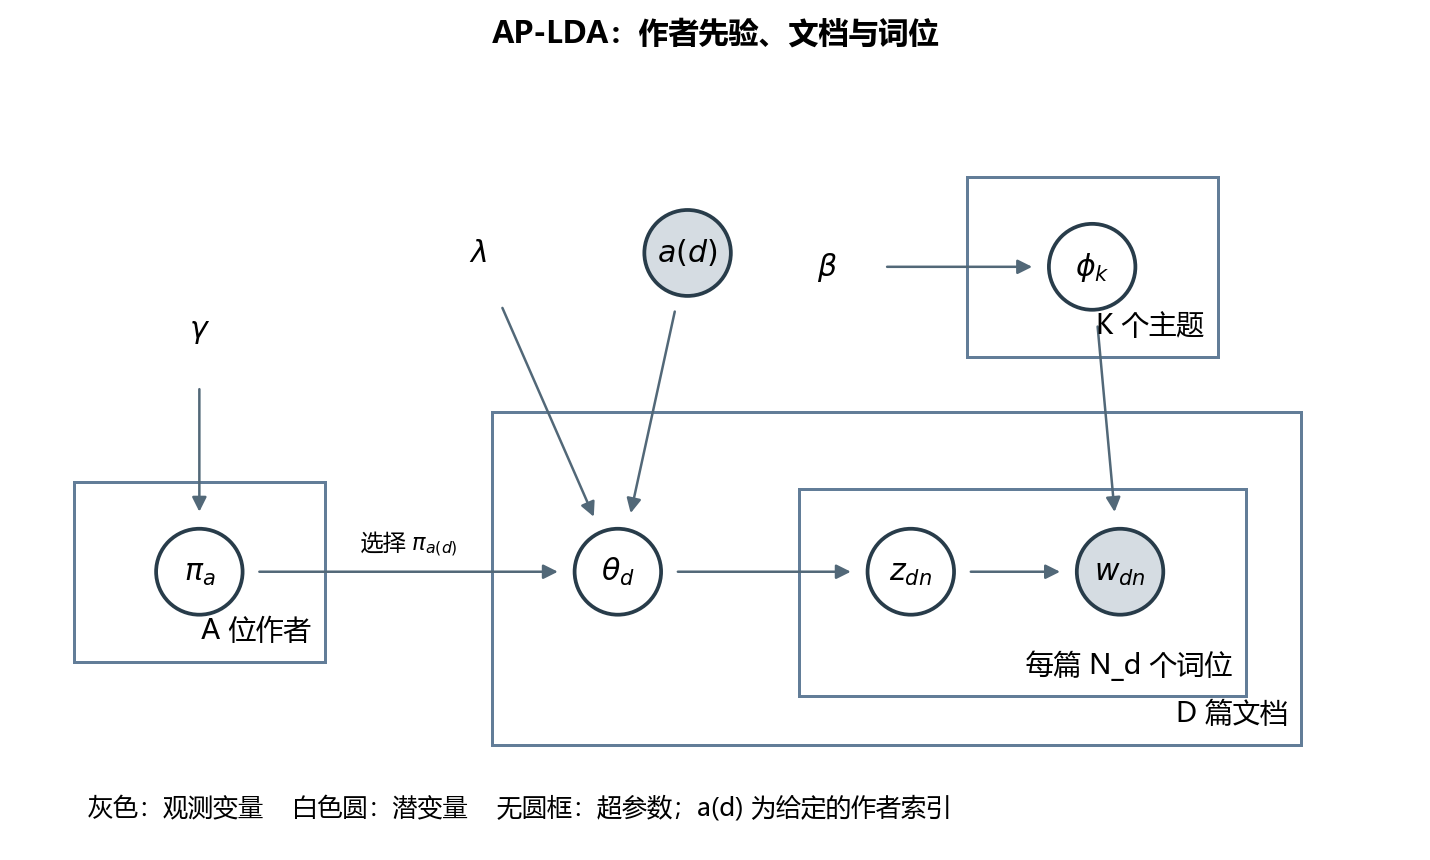

In [24]:
from src.visualization.plots import configure_style, plate_diagram
configure_style()
figure_dir = ROOT / "results/figures"
figure_dir.mkdir(parents=True, exist_ok=True)
for aware in [False, True]:
    name = "ap_lda_plate" if aware else "lda_plate"
    if not (figure_dir / f"{name}.png").exists():
        print(plate_diagram(figure_dir, aware))
    display(Image(filename=str(figure_dir / f"{name}.png"), width=850))

## 步骤 4：获取真实语料并确认来源

采用 UCI 的 **Reuter_50_50 / Reuters C50**：原始压缩包包含 50 位记者的 5000 篇新闻，官方训练和测试各 2500 篇。UCI 页面标示 CC BY 4.0；引用为 Liu, Z. (2006)，DOI: 10.24432/C5DS42。

注意它主要是企业/工业新闻，用来研究作者偏好是合理的小规模实验，但不能代表所有领域。这里使用语料提供的单记者文件夹标签，不猜测合著关系。

下载函数会复用已有文件、检查 ZIP 文档数、记录 URL 和 SHA256。它不会每次重新联网下载。

来源：[UCI 数据页](https://archive.ics.uci.edu/dataset/217/reuter+50+50)。

In [25]:
from src.data.download import download
archive = download(ROOT / "data/raw")
provenance = json.loads((ROOT / "data/raw/provenance.json").read_text(encoding="utf-8"))
print("压缩包：", archive)
print("字节数：", archive.stat().st_size)
display(pd.Series(provenance, name="数据来源与校验"))

压缩包： d:\项目文件夹\作者信息主题建模\data\raw\C50.zip
字节数： 8194031


url                https://archive.ics.uci.edu/static/public/217/...
landing_page       https://archive.ics.uci.edu/dataset/217/reuter...
citation           Liu, Z. (2006). Reuter_50_50. DOI: 10.24432/C5...
license_on_uci                                             CC BY 4.0
documents                                                       5000
sha256             d1de4af0f439c9ffd097dc30ea15fb22cb015e1cbfde98...
verified_at_utc                     2026-10-26T03:39:39.056707+00:00
Name: 数据来源与校验, dtype: object

## 步骤 5：划分数据，再学习词汇表

顺序非常重要：先固定作者和训练/验证/测试文档，再**仅在训练文本上拟合**词汇表。

预处理包括小写、英文词切分、停用词、记者姓名/来源词去除、过低/过高文档频率过滤。为控制计算量，每篇最多均匀抽取 220 个词位，重复词仍保留计数。四个模型读取完全相同的稀疏词袋。

官方测试文档不会混入训练。验证集从官方训练部分独立划出。精确重复被去除，并额外审计测试—训练的最大 TF-IDF 相似度。OOV 是不在训练词汇表中的词；其比例必须报告，因为后续评价仅覆盖词表内词。

默认复用已处理的数据；将 `REBUILD_DATA=True` 可按相同配置重新生成。

In [26]:
from src.data.preprocess import prepare, load_prepared
REBUILD_DATA = False
processed = ROOT / "data/processed"
if REBUILD_DATA or not (processed / "audit.json").exists():
    matrices, records, vocabulary, audit = prepare(archive, config["dataset"], processed)
else:
    matrices, records, vocabulary = load_prepared(processed)
    audit = json.loads((processed / "audit.json").read_text(encoding="utf-8"))

display(pd.DataFrame([
    {"划分": name, "文档数": info["documents"], "作者数": len(info["documents_per_author"]),
     "总词位": info["tokens_after_cap"], "OOV比例": info["oov_rate"]}
    for name, info in audit["splits"].items()
]))
print("词汇表大小：", len(vocabulary))
print("训练矩阵形状（文档数 × 词汇数）：", matrices["train"].shape)
print("作者标签：", audit["authors"])
print("精确重复剔除数：", audit["discarded_exact_duplicates_in_selected_authors"])
print("测试—训练最大相似度分位数：", audit["test_train_tfidf_max_similarity_quantiles"])

,划分,文档数,作者数,总词位,OOV比例
0,train,384,12,65302,0.265759
1,validation,144,12,24267,0.286831
2,test,240,12,38480,0.321810


词汇表大小： 1800
训练矩阵形状（文档数 × 词汇数）： (384, 1800)
作者标签： ['AaronPressman', 'BernardHickey', 'JimGilchrist', 'JoeOrtiz', 'KeithWeir', 'KevinMorrison', 'LydiaZajc', 'MartinWolk', 'RobinSidel', 'SarahDavison', 'ToddNissen', 'WilliamKazer']
精确重复剔除数： 5
测试—训练最大相似度分位数： [0.4542037084458107, 0.669719310406949, 0.886445486539817, 0.9158277419889259]


### 看懂词袋与映射

一行是一篇文档，一列是词汇表中的一个词，数值是出现次数。作者标签和文档 ID 单独保存，并与矩阵行一一对应。下面只查看一篇训练文档的前几个常见词。

In [27]:
example = matrices["train"].getrow(0)
print("文档 ID：", records["train"][0]["id"])
print("作者：", records["train"][0]["author"])
display(pd.DataFrame({"词": [vocabulary[i] for i in example.indices], "次数": example.data})
        .sort_values("次数", ascending=False).head(15))
assert not ({r["id"] for r in records["train"]} & {r["id"] for r in records["test"]})
assert all(m.shape[1] == len(vocabulary) for m in matrices.values())

文档 ID： C50train/AaronPressman/270134newsML.txt
作者： AaronPressman


,词,次数
19,banks,11
101,securities,10
50,fed,9
2,act,5
65,industry,4
33,congress,4
57,glass,3
53,financial,3
117,underwriting,3
100,section,3


## 步骤 6：先用已知真值的合成语料检验模型

真实新闻没有“作者真实主题概率”标签，所以不能直接声称恢复准确。合成验证则按指定模型生成 π、φ、θ 和文本，让我们可以比较估计与真值。

主题编号可以任意置换：估计的 T0 不一定对应生成时的 T0。因此先按主题词分布用 Hungarian 算法对齐，再计算作者 π 的平均绝对误差（MAE）。这一步与真实语料性能评价严格分开。

In [28]:
from src.models import AuthorPriorLDA
from src.data.synthetic import generate, align_topics
sx, sa, true_pi, true_phi, _ = generate()
synthetic_model = AuthorPriorLDA(
    n_topics=3, gamma=0.5, beta=0.05, lambda_author=12,
    n_iter=350, burn_in=150, thin=5, random_state=19,
).fit(sx, sa)
order = align_topics(synthetic_model.topic_words_, true_phi)
estimated_pi = synthetic_model.author_topics_[:, order]
print("【合成验证】作者偏好 MAE：", np.abs(estimated_pi - true_pi).mean())
display(pd.concat({
    "生成真值": pd.DataFrame(true_pi, columns=["T0", "T1", "T2"]),
    "估计偏好（已对齐）": pd.DataFrame(estimated_pi, columns=["T0", "T1", "T2"]),
}, axis=1))
print("概率行和：", estimated_pi.sum(1))
print("数值诊断：", synthetic_model.diagnostics_)

【合成验证】作者偏好 MAE： 0.01083413951177168


生成真值                     估计偏好（已对齐）                    
             T0        T1        T2        T0        T1        T2
0  4.599860e-02  0.000985  0.953017  0.047329  0.001046  0.951625
1  3.734303e-01  0.007861  0.618709  0.346762  0.007681  0.645558
2  6.458035e-07  0.674665  0.325335  0.001609  0.679524  0.318867
3  4.744346e-02  0.463149  0.489408  0.026035  0.461761  0.512203
4  4.405223e-01  0.043253  0.516225  0.413697  0.043192  0.543111
5  6.147658e-02  0.916750  0.021774  0.072772  0.903632  0.023595

概率行和： [1. 1. 1. 1. 1. 1.]
数值诊断： {'retained_samples': 40, 'n_tokens': 12960, 'entropy_ess': 51.657016638877664, 'max_normalization_error': 4.440892098500626e-16, 'all_finite': True}


## 步骤 7：训练真实语料上的四个模型

四个模型的区别：

| 模型 | 作用 |
| --- | --- |
| LDA-sklearn | 成熟的标准 LDA 变分实现 |
| LDA-Gibbs | 与 AP-LDA 共享词主题采样器，控制推断算法差异 |
| AP-LDA | 从真实作者标签推断作者偏好 |
| AP-shuffled | 把文档的作者标签随机置换，仍保持每位作者文档数 |

本节展示预先固定 K=10、λ=10 的第一个种子，便于快速理解。**不是挑选测试分数最高的模型。** 默认读取已有 checkpoint；将 `RETRAIN_DEMO=True` 可重新训练。完整三种子与超参数实验见步骤 11。

标准 LDA 的 α=λ/K，保证先验总浓度一致。Gibbs 与变分 EM 的轮次含义不同，因此完整结果另外报告训练耗时。

In [29]:
from src.evaluation.experiments import make_model, permute_authors, MODEL_NAMES
RETRAIN_DEMO = False
train_authors = [r["author"] for r in records["train"]]
validation_authors = [r["author"] for r in records["validation"]]
models = {}
for name in MODEL_NAMES:
    key = f"{name}_K{cfg['n_topics']}_lambda{cfg['lambda_author']:g}_n{config['dataset']['train_per_author']}_s{SEED}"
    checkpoint = ROOT / "results/checkpoints" / f"{key}.npz"
    if checkpoint.exists() and not RETRAIN_DEMO:
        models[name] = AuthorPriorLDA.load(checkpoint)
        print(name, "：读取已有模型")
    else:
        labels = permute_authors(train_authors, SEED) if name == "AP-shuffled" else train_authors
        models[name] = make_model(name, cfg["n_topics"], cfg["lambda_author"], SEED, cfg)
        with threadpool_limits(limits=1):
            models[name].fit(matrices["train"], labels)
        models[name].save(checkpoint)
        print(name, "：训练并保存完成")
ap_model = models["AP-LDA"]
print("作者后验样本形状：", ap_model.author_samples_.shape)
print("训练数值诊断：", ap_model.diagnostics_)

LDA-sklearn ：读取已有模型
LDA-Gibbs ：读取已有模型
AP-LDA ：读取已有模型
AP-shuffled ：读取已有模型
作者后验样本形状： (20, 12, 10)
训练数值诊断： {'retained_samples': 20, 'n_tokens': 65302, 'entropy_ess': 3.3150393565707468, 'max_normalization_error': 4.440892098500626e-16, 'all_finite': True}


## 步骤 8：读懂主题、作者偏好与文档主题

主题本身由 φ 的高概率关键词解释；作者偏好 π 与文档分布 θ 使用同一组主题编号。主题编号只是模型内部的名字，跨种子比较前需要对齐。

下面依次输出主题关键词、全部作者偏好、前几篇文档主题。作者分布不是按词频直接生成，而是训练期间 π 的后验样本均值。

In [30]:
phi = ap_model.get_topic_word_distribution()
pi = ap_model.get_author_topic_distribution()
topic_columns = [f"T{k}" for k in range(ap_model.n_topics)]
topic_names = {
    f"T{k}": ", ".join(vocabulary[i] for i in np.argsort(phi[k])[-10:][::-1])
    for k in range(ap_model.n_topics)
}
display(pd.Series(topic_names, name="Top-10 关键词").to_frame())
author_topics = pd.DataFrame(pi, index=ap_model.author_ids_, columns=topic_columns)
display(author_topics.round(3))
document_topics = pd.DataFrame(ap_model.document_topics_, columns=topic_columns)
document_topics.insert(0, "author", train_authors)
document_topics.insert(0, "document_id", [r["id"] for r in records["train"]])
display(document_topics.head())

,Top-10 关键词
T0,"cargo, toronto, gold, stocks, canada, air, ind..."
T1,"percent, million, sales, quarter, profit, ford..."
T2,"million, pounds, television, british, microsof..."
T3,"news, corp, australian, murdoch, sydney, media..."
T4,"percent, bank, market, billion, stock, share, ..."
T5,"china, fund, foreign, state, states, funds, go..."
T6,"internet, companies, computer, banks, software..."
T7,"hong, kong, china, conrail, csx, southern, nor..."
T8,"company, business, time, chairman, shareholder..."
T9,"boeing, industry, business, years, customers, ..."


,T0,T1,T2,T3,T4,T5,T6,T7,T8,T9
AaronPressman,0.002,0.036,0.030,0.005,0.066,0.082,0.551,0.001,0.170,0.058
BernardHickey,0.017,0.198,0.061,0.251,0.207,0.049,0.014,0.003,0.146,0.053
JimGilchrist,0.308,0.064,0.033,0.034,0.030,0.062,0.041,0.192,0.111,0.124
JoeOrtiz,0.009,0.078,0.113,0.010,0.245,0.099,0.050,0.007,0.289,0.100
KeithWeir,0.003,0.085,0.339,0.060,0.170,0.055,0.037,0.008,0.162,0.082
KevinMorrison,0.070,0.136,0.048,0.196,0.266,0.049,0.016,0.012,0.156,0.049
LydiaZajc,0.496,0.133,0.013,0.025,0.184,0.041,0.020,0.004,0.071,0.012
MartinWolk,0.029,0.215,0.103,0.022,0.134,0.020,0.090,0.001,0.197,0.189
RobinSidel,0.001,0.090,0.001,0.006,0.337,0.028,0.019,0.034,0.372,0.111
SarahDavison,0.013,0.072,0.021,0.015,0.141,0.213,0.063,0.216,0.176,0.070


,document_id,author,T0,T1,T2,T3,T4,T5,T6,T7,T8,T9
0,C50train/AaronPressman/270134newsML.txt,AaronPressman,0.019961,0.005062,0.002390,0.000710,0.120607,0.050359,0.594304,0.000026,0.159077,0.047504
1,C50train/AaronPressman/156814newsML.txt,AaronPressman,0.000785,0.028347,0.015295,0.004559,0.022177,0.155365,0.614427,0.000938,0.133548,0.024559
2,C50train/AaronPressman/136958newsML.txt,AaronPressman,0.000934,0.005478,0.056248,0.002437,0.041070,0.079755,0.439997,0.000030,0.335310,0.038742
3,C50train/AaronPressman/231479newsML.txt,AaronPressman,0.000095,0.021991,0.012172,0.000428,0.014160,0.074239,0.607650,0.000024,0.231291,0.037950
4,C50train/AaronPressman/270346newsML.txt,AaronPressman,0.000129,0.004485,0.003844,0.000878,0.154774,0.053106,0.586447,0.000033,0.170988,0.025316


### 同一位作者为什么有不同的文档分布？

π 表达共同偏好，θ 表达某一篇文档。λ 有限时，模型允许作者切换报道主题。下面选择固定的第一位作者和其前三篇训练文档；无需凭主观印象挑例子。

In [31]:
author = ap_model.author_ids_[0]
display(author_topics.loc[[author]].round(3))
display(document_topics[document_topics.author == author].head(3).round(3))
print("这位作者最偏好的主题：", author_topics.loc[author].idxmax())
print("该主题关键词：", topic_names[author_topics.loc[author].idxmax()])

,T0,T1,T2,T3,T4,T5,T6,T7,T8,T9
AaronPressman,0.002,0.036,0.03,0.005,0.066,0.082,0.551,0.001,0.17,0.058


,document_id,author,T0,T1,T2,T3,T4,T5,T6,T7,T8,T9
0,C50train/AaronPressman/270134newsML.txt,AaronPressman,0.020,0.005,0.002,0.001,0.121,0.050,0.594,0.000,0.159,0.048
1,C50train/AaronPressman/156814newsML.txt,AaronPressman,0.001,0.028,0.015,0.005,0.022,0.155,0.614,0.001,0.134,0.025
2,C50train/AaronPressman/136958newsML.txt,AaronPressman,0.001,0.005,0.056,0.002,0.041,0.080,0.440,0.000,0.335,0.039


这位作者最偏好的主题： T6
该主题关键词： internet, companies, computer, banks, software, access, service, congress, rules, online


## 步骤 9：新文档推断、未知作者与模型保存

`transform` 使用训练时同一套词 ID/列顺序。对已知作者使用已训练 π 的均值，对未知作者则在这一篇观察文本内部联合推断局部 π；不会把测试文本送回训练去改变全局主题或历史作者偏好。

这里选取验证集的两篇词袋演示接口。**这不是测试指标**，且不重新估计全局参数。批量推断、缺失作者标识与保存/加载均可使用。

In [32]:
new_docs = matrices["validation"][:2]
known = [records["validation"][i]["author"] for i in range(2)]
theta_known = ap_model.transform(new_docs, known)
theta_unseen = ap_model.transform(new_docs, ["new-author", None])
display(pd.DataFrame(theta_known, columns=topic_columns).round(3))
display(pd.DataFrame(theta_unseen, columns=topic_columns).round(3))

notebook_dir = ROOT / "results/notebook"
notebook_dir.mkdir(parents=True, exist_ok=True)
ap_model.save(notebook_dir / "AP-LDA.npz")
reloaded = AuthorPriorLDA.load(notebook_dir / "AP-LDA.npz")
np.testing.assert_array_equal(theta_known, reloaded.transform(new_docs, known))
print("保存/加载前后预测完全一致；每行概率和：", theta_known.sum(1))

,T0,T1,T2,T3,T4,T5,T6,T7,T8,T9
0,0.0,0.009,0.006,0.000,0.063,0.123,0.528,0.0,0.263,0.008
1,0.0,0.022,0.007,0.019,0.067,0.044,0.588,0.0,0.148,0.106


,T0,T1,T2,T3,T4,T5,T6,T7,T8,T9
0,0.005,0.003,0.002,0.004,0.054,0.121,0.511,0.019,0.280,0.002
1,0.001,0.020,0.004,0.025,0.077,0.039,0.578,0.001,0.147,0.109


保存/加载前后预测完全一致；每行概率和： [1. 1.]


## 步骤 10：公平地评价文档完成能力

不能把 sklearn 的训练困惑度与 AP-LDA 的训练 log 密度直接比较。我们把每篇验证文档的**词位**随机分成观察部分 O 与预测部分 H：

1. 所有模型看到完全相同的 O，使用同一个局部 Gibbs 采样器估计 θ。
2. H 不参加 θ、π、φ 的估计，仅用于评分。
3. 所有模型都用相同定义：

$$\ell=\frac{\sum_d\sum_{w\in H_d}\log(\widehat\theta_d\widehat\phi)_w}{\sum_d|H_d|},\qquad\mathrm{PPL}=e^{-\ell}.$$

每词 log 概率越高越好，PPL 越低越好。这里固定全局参数的后验均值，是 **plug-in 单词边缘预测**，不是完整贝叶斯文档联合证据。

同时计算文档窗口 C_NPMI（关键词共现一致性）与主题多样性。两者与预测能力是不同维度，可能出现取舍。

In [33]:
from src.evaluation.metrics import split_completion, completion_score, topic_metrics
observed, heldout = split_completion(matrices["validation"], fraction=0.5, seed=991)
assert (observed + heldout != matrices["validation"]).nnz == 0
reference = sparse.load_npz(processed / "train_full.npz")
validation_results = []
for name, model in models.items():
    labels = permute_authors(validation_authors, SEED + 1) if name == "AP-shuffled" else validation_authors
    score = completion_score(model, observed, heldout, labels, seed=1201)
    quality = topic_metrics(model.topic_words_, reference, cfg["top_m"])
    validation_results.append({"模型": name, "每词log概率↑": score["log_probability"],
        "完成困惑度↓": score["perplexity"], "C_NPMI↑": quality["npmi"], "主题多样性↑": quality["diversity"]})
display(pd.DataFrame(validation_results).set_index("模型").round(4))
print("这是单种子验证结果；正式比较需要看三种子均值和波动。")

,每词log概率↑,完成困惑度↓,C_NPMI↑,主题多样性↑
模型,,,,
LDA-sklearn,-6.6666,785.7319,0.2247,0.84
LDA-Gibbs,-6.6659,785.2072,0.2237,0.86
AP-LDA,-6.6905,804.7241,0.0966,0.91
AP-shuffled,-6.6571,778.2975,0.2363,0.88


这是单种子验证结果；正式比较需要看三种子均值和波动。


## 步骤 11：完整的三种子、超参数与消融实验

完整脚本执行：

1. 固定 K，扫描 λ = 1、5、10、20、50、100。
2. 每个模型按三种子的平均验证分数选择 λ，再扫描 K = 5、10、15、20、30。
3. 在任何测试评分前，保存 `selection.json`，冻结配置。
4. 分别比较每作者 4、12、32 篇训练文档；数据划分不变。
5. 对预声明固定配置和验证集选择配置，评价测试集 10%/50% 观察比例。
6. 输出全部原始指标、模型、日志、图和中文报告。

这是**顺序搜索**而非 K×λ 完整联合网格。默认不重复已有完整实验；将下方开关改为 `True` 可执行，脚本支持复用已有配置结果。若修改 YAML，请同时指定新的 `--output` 目录，避免混淆不同配置的结果。

In [34]:
RUN_FULL_EXPERIMENTS = False
command = [sys.executable, "-m", "scripts.run_experiments", "--config", "configs/default.yaml"]
print("完整实验命令：", " ".join(command))
if RUN_FULL_EXPERIMENTS:
    subprocess.run(command, cwd=ROOT, check=True)
else:
    print("当前读取项目已完成的实际实验；需要重跑时将 RUN_FULL_EXPERIMENTS 改为 True。")

selection_path = ROOT / "results/metrics/selection.json"
if selection_path.exists():
    selection = json.loads(selection_path.read_text(encoding="utf-8"))
    display(pd.DataFrame(selection["models"]).T.rename(columns={"lambda": "λ"}))
    print("测试集是否用于选择：", selection["test_used_for_selection"])
    print("配置冻结时间（UTC）：", selection["frozen_at_utc"])
else:
    print("尚未完成全套实验。先运行上方命令，之后再看测试结果。")

完整实验命令： d:\Softwares\Anaconda\envs\test1\python.exe -m scripts.run_experiments --config configs/default.yaml
当前读取项目已完成的实际实验；需要重跑时将 RUN_FULL_EXPERIMENTS 改为 True。


,K,λ
LDA-sklearn,30.0,5.0
LDA-Gibbs,30.0,1.0
AP-LDA,30.0,20.0
AP-shuffled,30.0,1.0


测试集是否用于选择： False
配置冻结时间（UTC）： 2026-10-26T03:10:01.627524+00:00


## 步骤 12：读取正式测试结果——三种子均值与标准差

`matched-fixed` 固定各模型相同的 K/λ，适合判断作者信息的作用。`validation-selected` 允许模型分别使用验证集选择的 K/λ，比较各自配置的泛化表现。

以下标准差是三个随机种子的**样本标准差**，反映初始化与采样的变异；不是跨数据集置信区间。不要只选均值最好的一条链。

In [35]:
test_path = ROOT / "results/metrics/test_scores.csv"
if test_path.exists():
    test_scores = pd.read_csv(test_path)
    for protocol in ["matched-fixed", "validation-selected"]:
        display(Markdown(f"### {protocol}：观察 50% 词位"))
        sub = test_scores[(test_scores.protocol == protocol) & (test_scores.observation_fraction == 0.5)]
        display(sub.groupby("model")[["log_probability", "perplexity", "npmi", "diversity"]]
                .agg(["mean", "std"]).round(4))
    primary = test_scores[(test_scores.protocol == "matched-fixed") & (test_scores.observation_fraction == 0.5)]
    means = primary.groupby("model").log_probability.mean()
    print("AP-LDA − 相同采样器 LDA 的每词 log 概率差：", means["AP-LDA"] - means["LDA-Gibbs"])
    print("AP-LDA − 作者置换对照的差：", means["AP-LDA"] - means["AP-shuffled"])
else:
    print("测试结果尚未生成；请先执行完整实验。")

### matched-fixed：观察 50% 词位

log_probability         perplexity             npmi          \
                       mean     std       mean      std    mean     std   
model                                                                     
AP-LDA              -6.6969  0.0366   810.2914  29.9136  0.2027  0.0968   
AP-shuffled         -6.7068  0.0133   818.0179  10.9226  0.2194  0.0181   
LDA-Gibbs           -6.7290  0.0080   836.3388   6.6870  0.2091  0.0470   
LDA-sklearn         -6.7353  0.0152   841.6653  12.8013  0.1926  0.0303   

            diversity          
                 mean     std  
model                          
AP-LDA         0.8867  0.0208  
AP-shuffled    0.8867  0.0115  
LDA-Gibbs      0.8633  0.0153  
LDA-sklearn    0.8433  0.0153

### validation-selected：观察 50% 词位

log_probability         perplexity            npmi          \
                       mean     std       mean     std    mean     std   
model                                                                    
AP-LDA              -6.5640  0.0055   709.1216  3.8631  0.1971  0.0180   
AP-shuffled         -6.5998  0.0069   734.9758  5.0502  0.2415  0.0142   
LDA-Gibbs           -6.6197  0.0024   749.6911  1.8210  0.1890  0.0115   
LDA-sklearn         -6.6201  0.0027   749.9854  2.0568  0.1677  0.0218   

            diversity          
                 mean     std  
model                          
AP-LDA         0.7911  0.0117  
AP-shuffled    0.7467  0.0088  
LDA-Gibbs      0.7522  0.0069  
LDA-sklearn    0.7144  0.0051

AP-LDA − 相同采样器 LDA 的每词 log 概率差： 0.032067946432768224
AP-LDA − 作者置换对照的差： 0.00988028725211354


## 步骤 13：图形解读

依次查看模型对比、λ 敏感性、K 敏感性、作者训练文档数影响和作者偏好热力图。误差棒为三种子的标准差。

- λ/K/文档数曲线使用验证分数，测试集未参与选择。
- 作者热力图属于定性解释，真实语料没有人工 π 真值，不能把图形当成偏好识别准确率。
- 主题多样性高不一定预测最好；需要一起看指标和不确定性。

**固定配置的真实测试集比较：观察误差棒与指标取舍。**

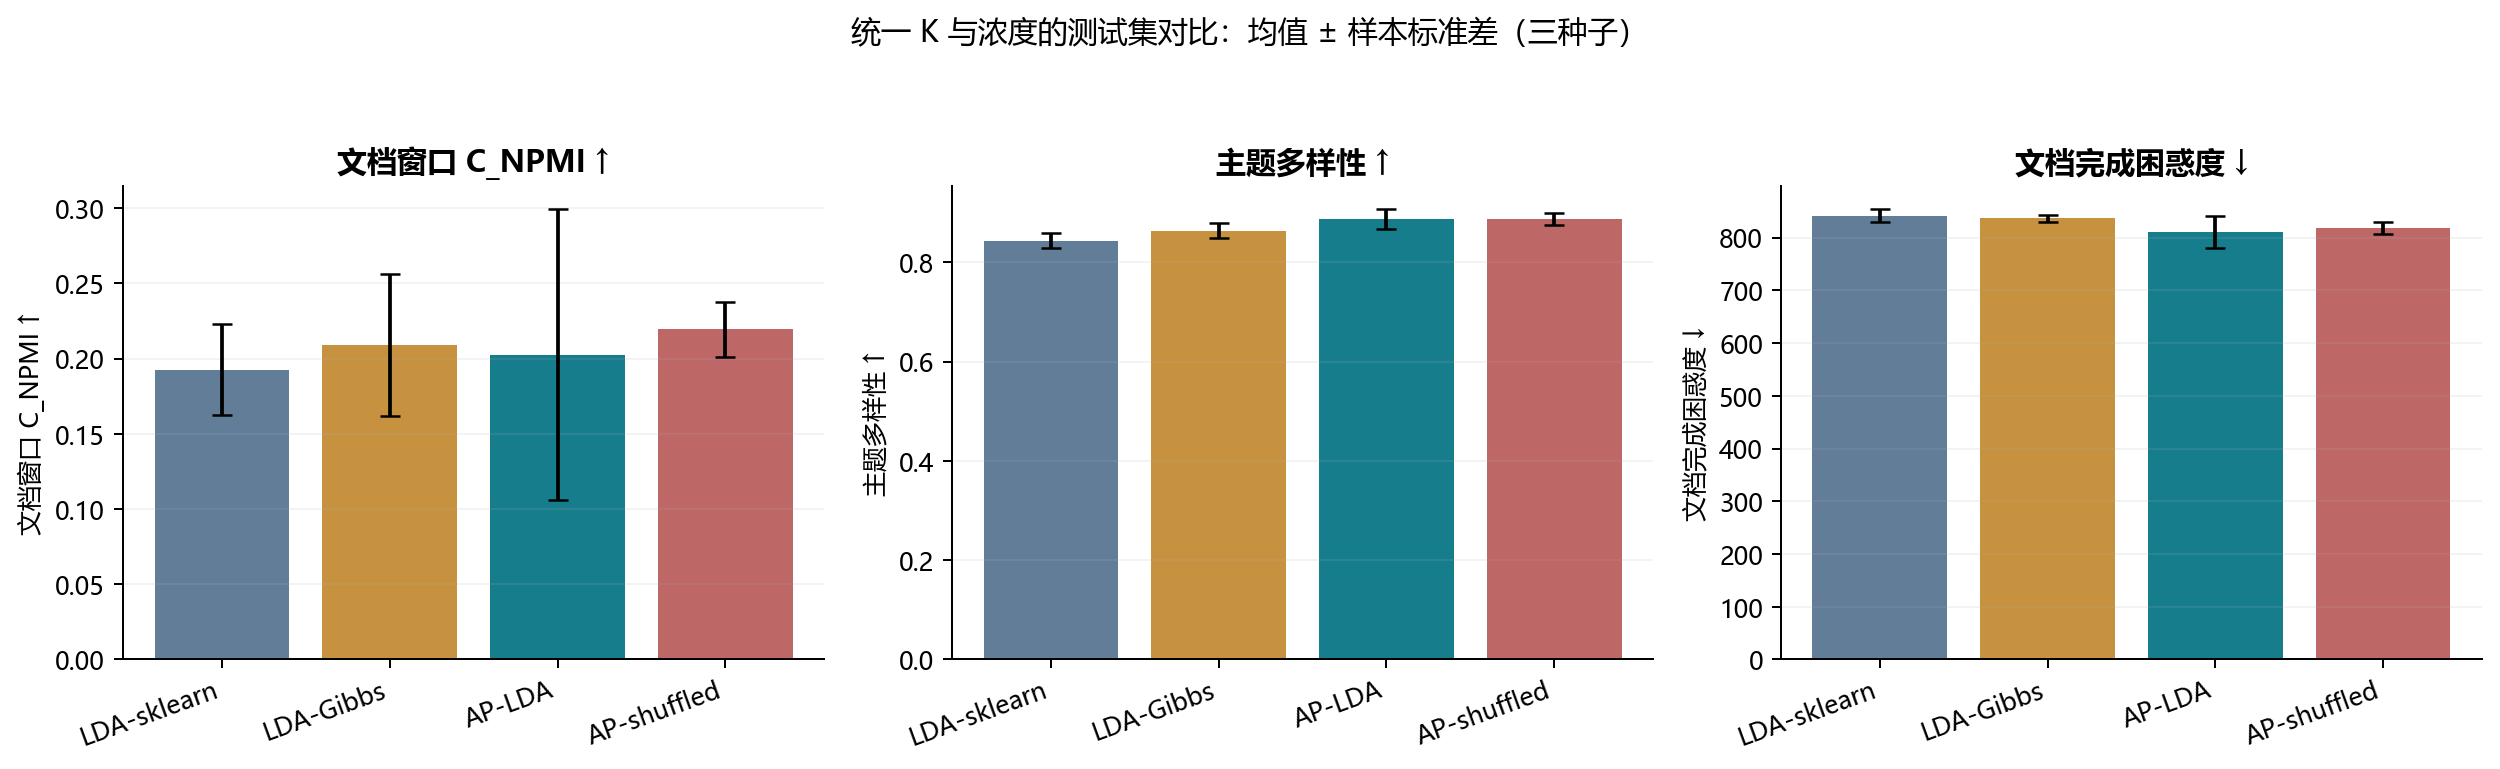

**λ 的影响：共享过强或过弱都可能影响效果。**

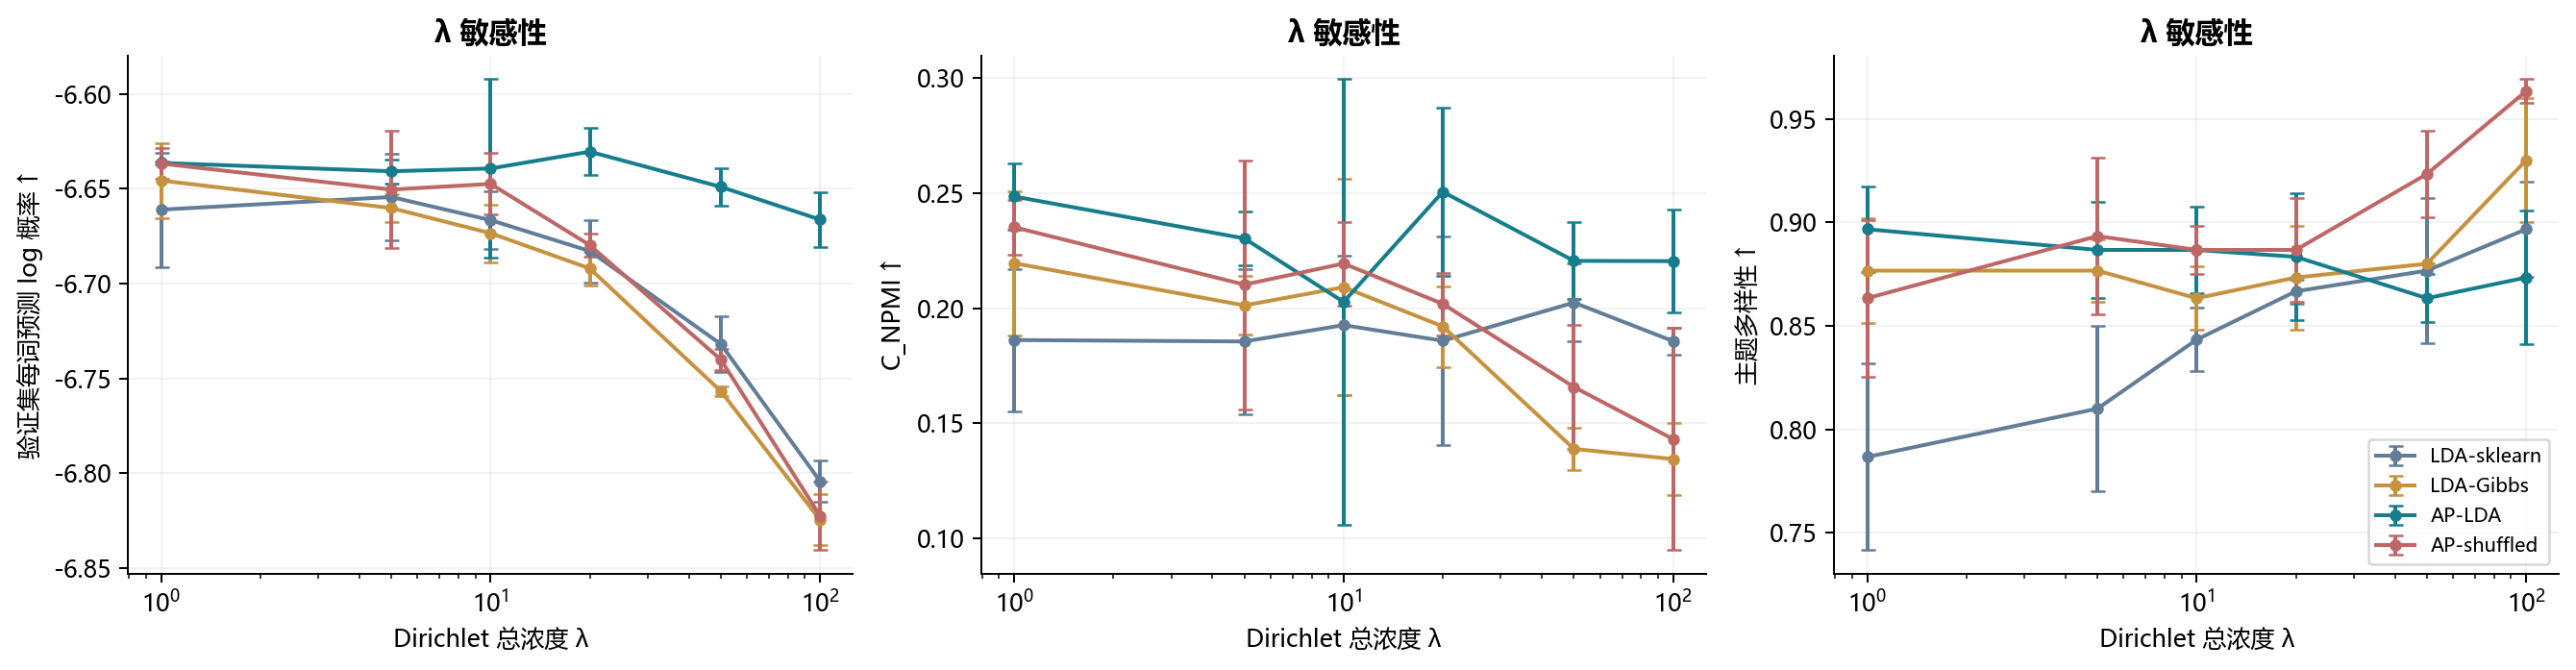

**主题数的影响：每个模型使用验证集所选的 λ。**

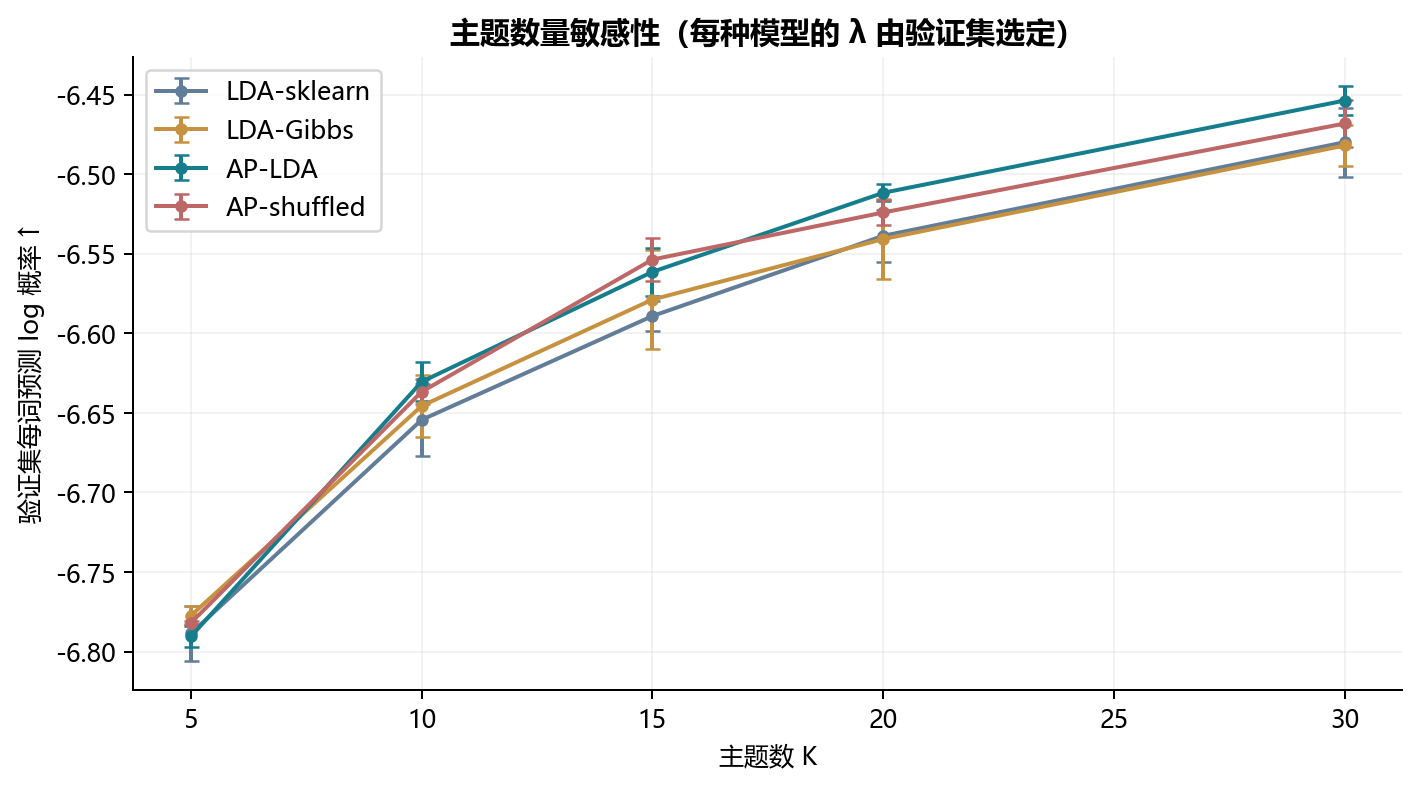

**每位作者训练文档数改变时，预测分数如何变化。**

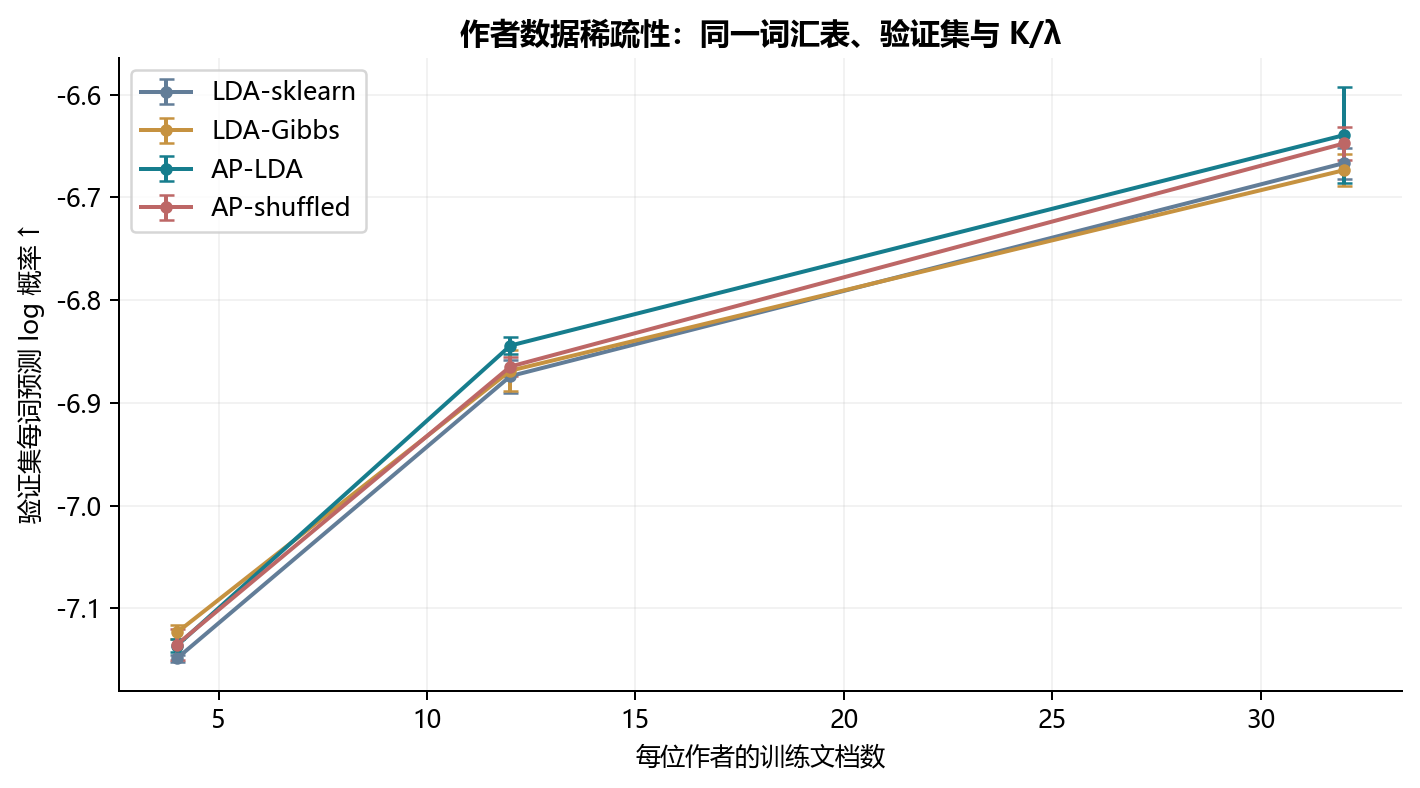

**同一主题空间中，不同作者的偏好分布。**

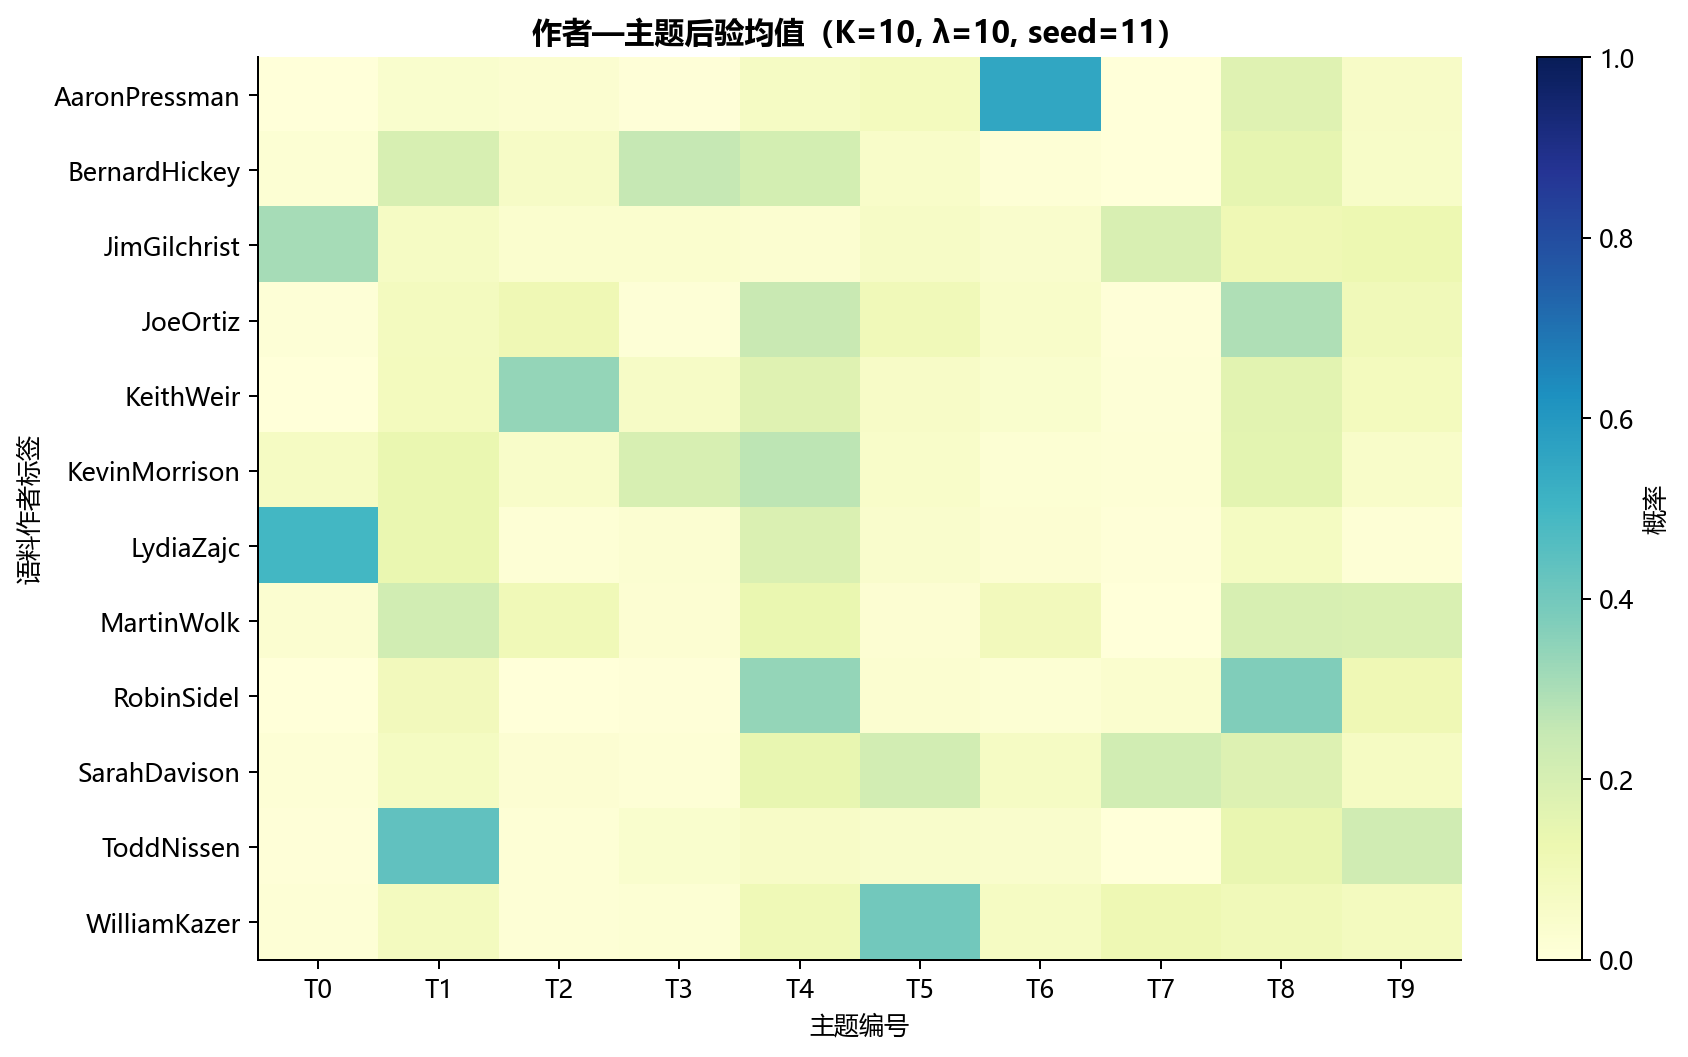

**相同作者的不同文档仍可有不同主题比例。**

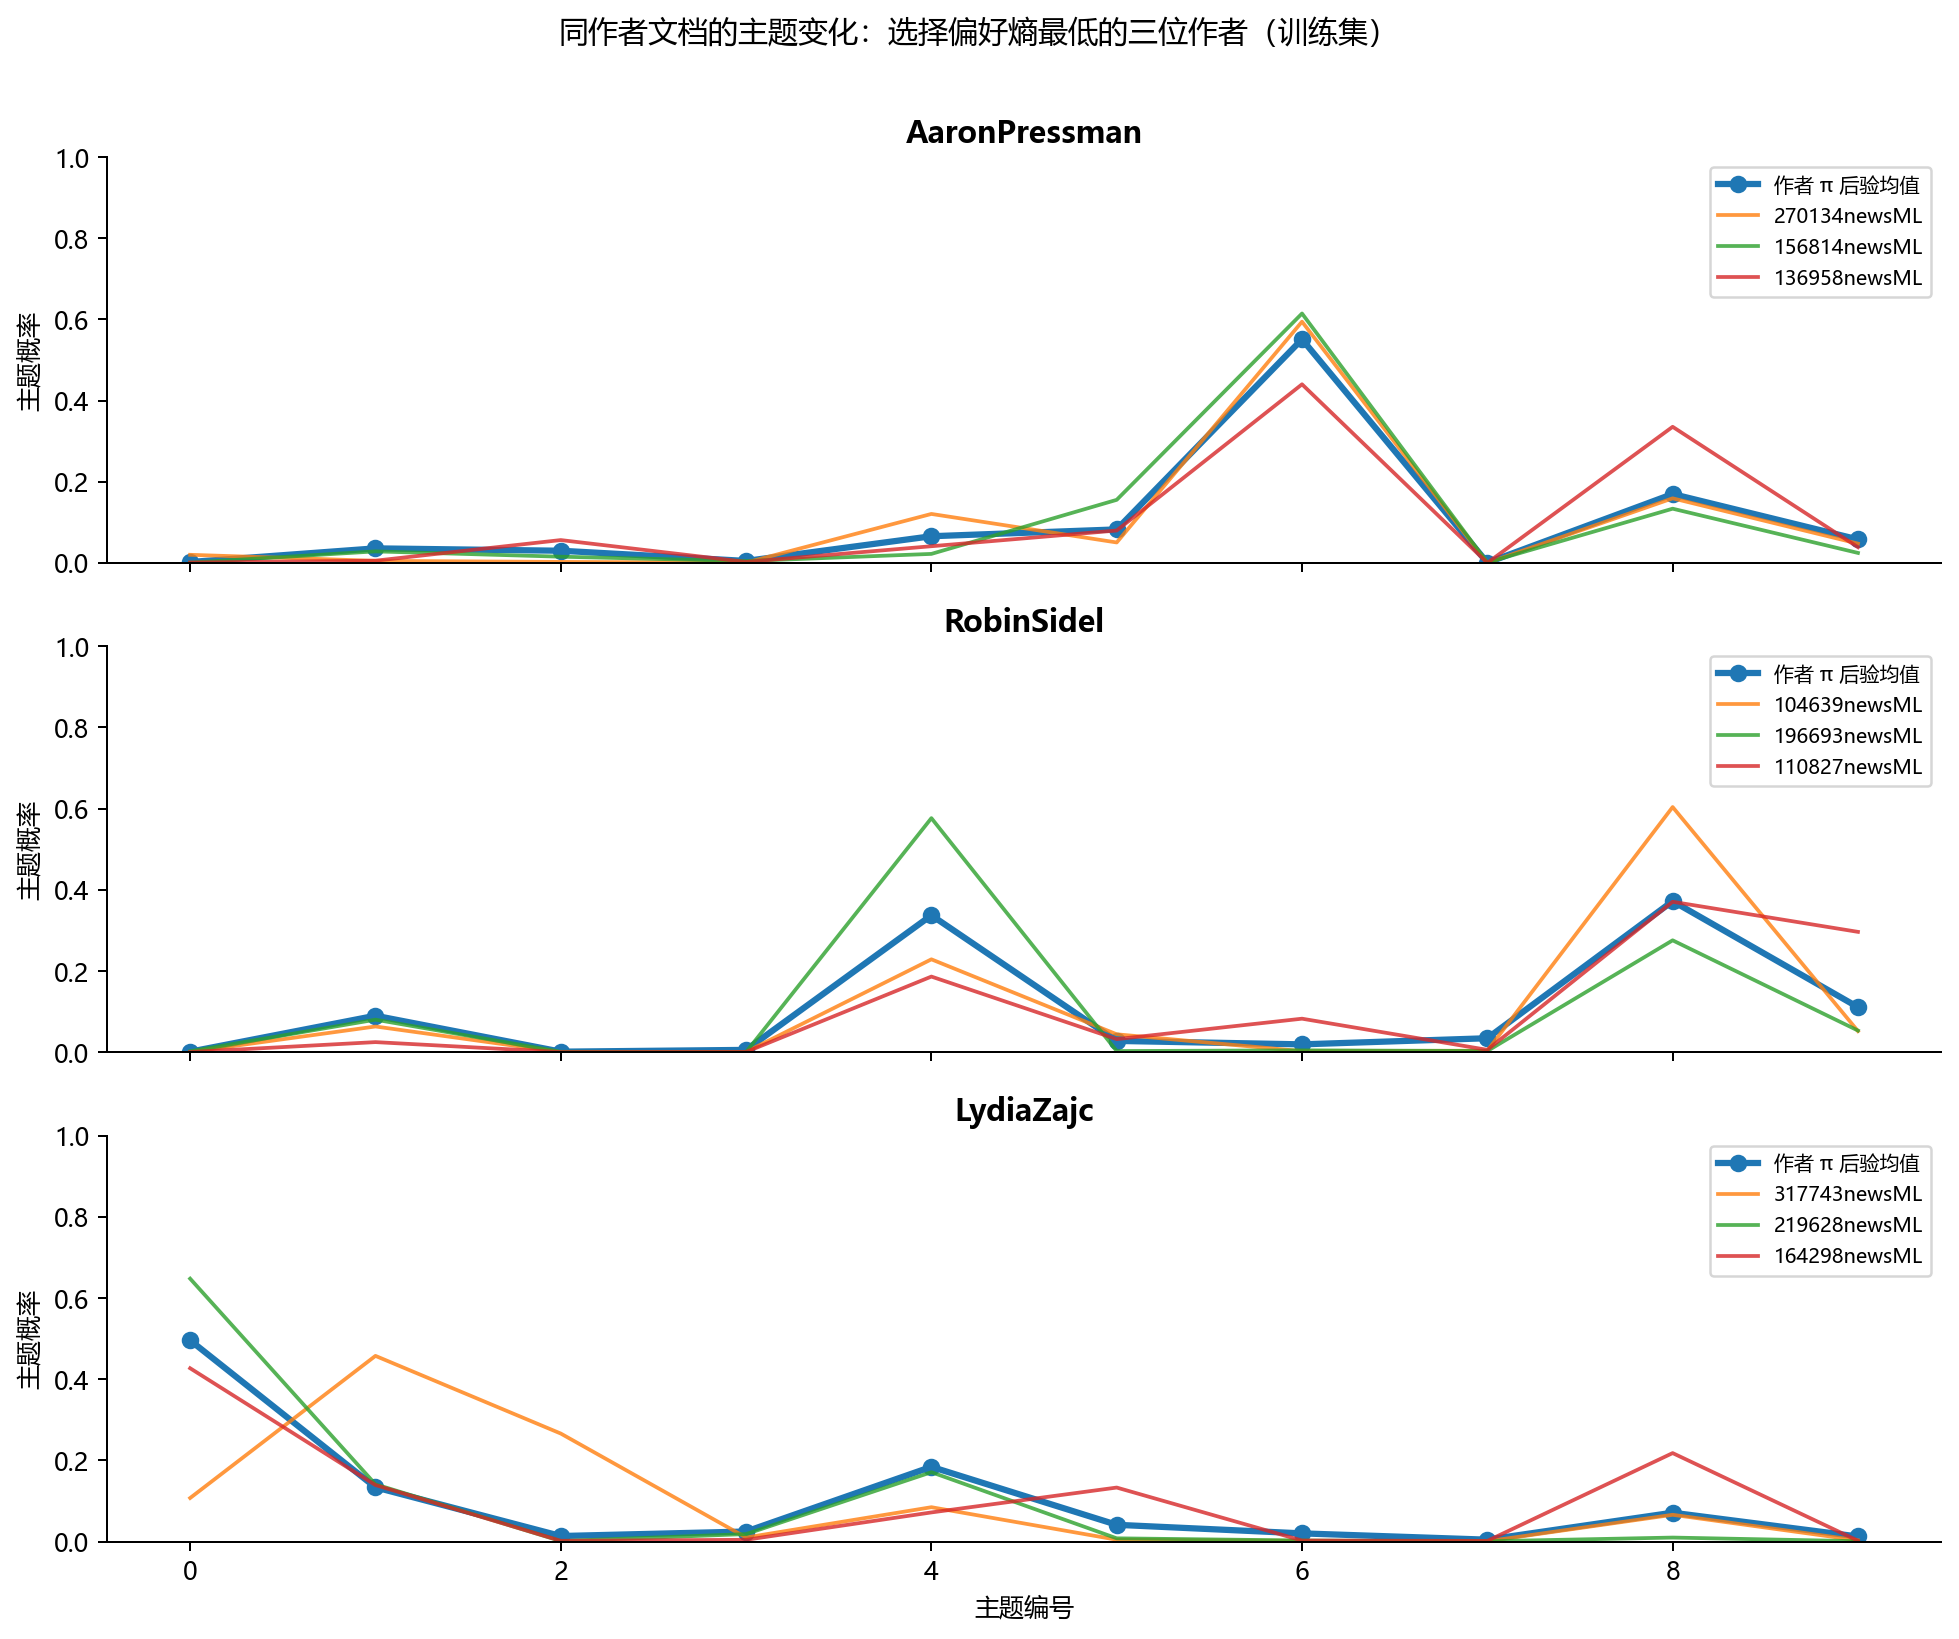

In [36]:
for figure, explanation in [
    ("model_comparison", "固定配置的真实测试集比较：观察误差棒与指标取舍。"),
    ("lambda_sensitivity", "λ 的影响：共享过强或过弱都可能影响效果。"),
    ("topic_sensitivity", "主题数的影响：每个模型使用验证集所选的 λ。"),
    ("author_data_sensitivity", "每位作者训练文档数改变时，预测分数如何变化。"),
    ("author_topic_heatmap", "同一主题空间中，不同作者的偏好分布。"),
    ("within_author_documents", "相同作者的不同文档仍可有不同主题比例。"),
]:
    path = figure_dir / f"{figure}.png"
    if path.exists():
        display(Markdown(f"**{explanation}**"))
        display(Image(filename=str(path), width=950))

## 步骤 14：采样诊断与结果边界

MCMC 能运行不代表数学正确，也不代表已充分收敛。这里同时依靠解析/数值对照测试与链诊断。

`split R-hat` 比较不同链与链内波动，接近 1 更理想；较大的值提示不同链尚未探索相同分布。`ESS` 是有效样本数，较低表示自相关较强。作者熵对主题编号置换不敏感，适合跨链检查，但它只是一个标量，不能证明整个主题矩阵收敛。

训练轨迹左侧的联合 log 密度与右侧 sklearn 训练困惑度定义不同，不能直接比较数值。长链诊断若可用，也仅作补充分析，不用测试集来反过来挑训练预算。

作者熵 split R-hat： 3.920805179607356


,retained_samples,n_tokens,entropy_ess,max_normalization_error,all_finite
0,20,65302,3.315039,4.440892e-16,True
1,20,65302,3.635284,3.330669e-16,True
2,20,65302,3.102984,3.330669e-16,True


解释限制： Scalar entropy diagnostics do not establish topic/label mixing or full posterior convergence.


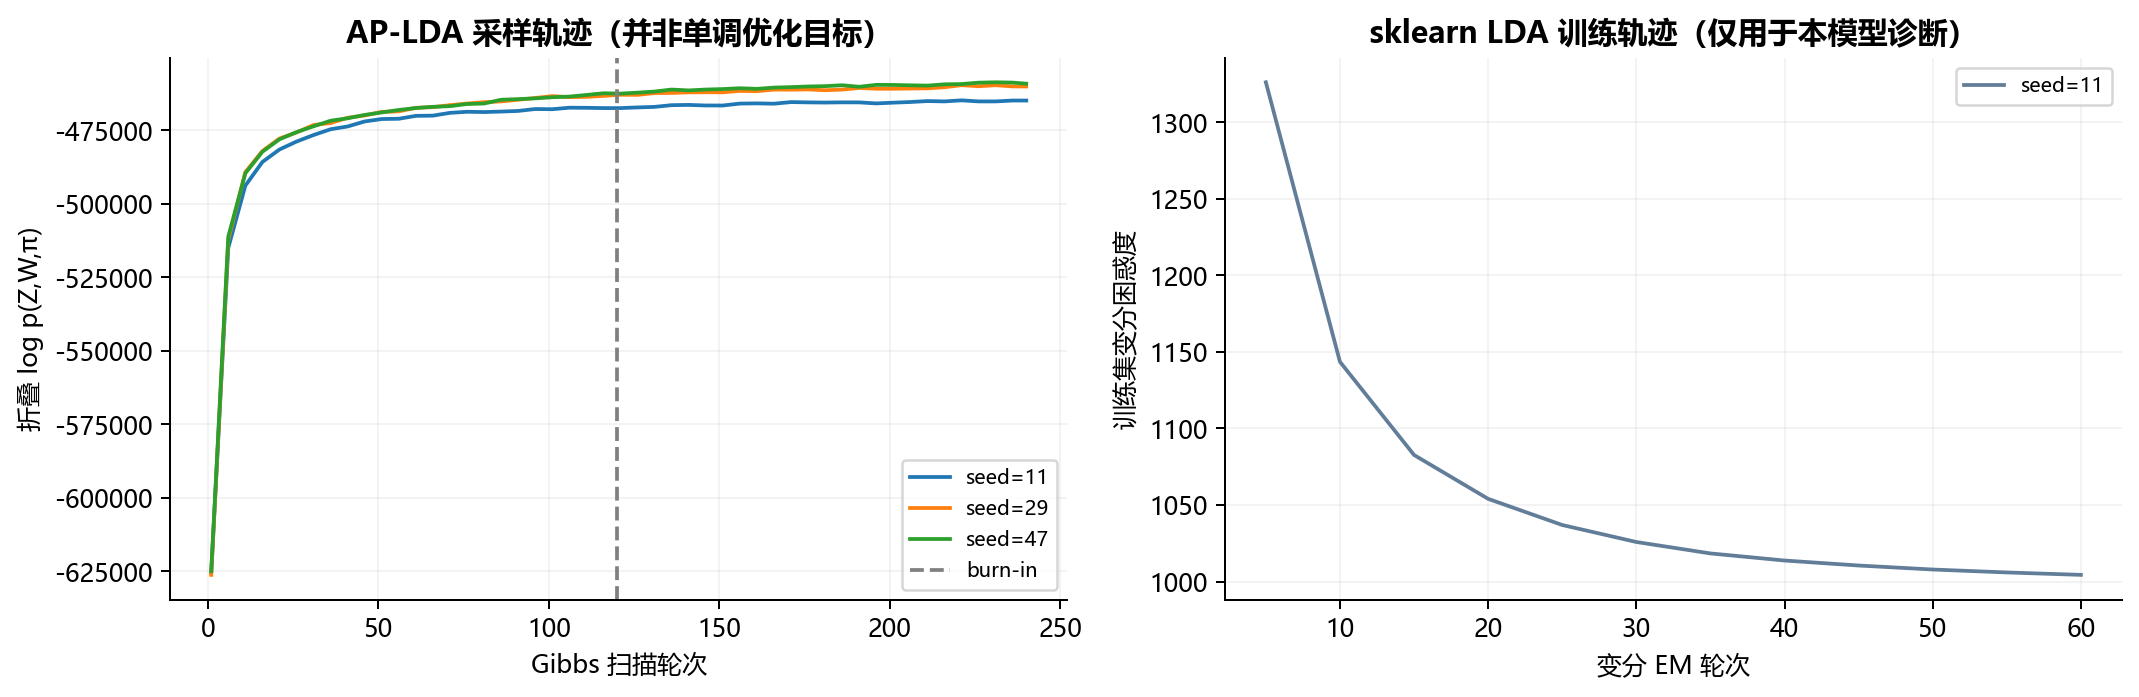

补充长链作者熵 R-hat： 1.8226567645272775


,seed,n_iter,burn_in,thin,entropy_ess,validation_log_probability,train_seconds
0,11,2400,1200,40,18.197876,-6.601225,10.648904
1,29,2400,1200,40,84.279812,-6.591343,12.399840
2,47,2400,1200,40,9.774484,-6.578298,10.793438


In [37]:
diagnostics_path = ROOT / "results/metrics/mcmc_diagnostics.json"
if diagnostics_path.exists():
    diagnostics = json.loads(diagnostics_path.read_text(encoding="utf-8"))
    print("作者熵 split R-hat：", diagnostics["entropy_split_rhat"])
    display(pd.DataFrame(diagnostics["chains"]))
    print("解释限制：", diagnostics["warning"])
if (figure_dir / "training_convergence.png").exists():
    display(Image(filename=str(figure_dir / "training_convergence.png"), width=1000))
long_path = ROOT / "results/metrics/long_chain_diagnostics.json"
if long_path.exists():
    long_diagnostics = json.loads(long_path.read_text(encoding="utf-8"))
    print("补充长链作者熵 R-hat：", long_diagnostics["entropy_split_rhat"])
    display(pd.DataFrame(long_diagnostics["runs"]))

## 步骤 15：运行测试，检查实现可靠性

测试不限于“程序能跑”：包括非共轭作者后验与数值积分对照、极小语料枚举后验、CRT 期望、词主题条件概率、理论矩、合成偏好恢复、作者置换影响、防止预测词污染训练、随机种子复现、空/未知作者与保存加载。

下面调用当前 Notebook 内核对应的 Python，避免把测试运行到另一个环境。返回码为 0 才表示测试通过。

In [38]:
test_run = subprocess.run([sys.executable, "-m", "pytest", "-q"], cwd=ROOT,
                          capture_output=True, text=True, encoding="utf-8", errors="replace")
print(test_run.stdout)
if test_run.stderr:
    print(test_run.stderr)
(ROOT / "results/logs").mkdir(parents=True, exist_ok=True)
(ROOT / "results/logs/tests.txt").write_text(test_run.stdout + test_run.stderr, encoding="utf-8")
assert test_run.returncode == 0, "存在未通过的测试，请检查上方输出"

.........................                                                [100%]
25 passed in 6.01s



## 步骤 16：保存本次演示分布，阅读完整报告

这些 CSV 可以直接用 Excel 或 pandas 查看。完整多种子结果、作者簇 bootstrap 区间、参数敏感性、模型优势与局限详见中文报告。

**应怎样回答研究问题？** 综合固定配置、验证选择后的比较、置换对照和波动来判断。作者偏好稳定、历史文档充分、观察文本短时可能有帮助；标签无信息、作者兴趣变化或先验约束过强时可能无效。结论必须以这里的实际结果为准。

尚未覆盖全量 50 作者、跨领域语料、多作者、时间变化及全参数充分混合的长期诊断。模型的实用接口已实现，但这些研究扩展需要单独实验，不能由当前图形推断。

In [39]:
author_topics.to_csv(notebook_dir / "author_topics.csv", encoding="utf-8-sig", index_label="author")
document_topics.to_csv(notebook_dir / "document_topics.csv", encoding="utf-8-sig", index=False)
pd.Series(topic_names, name="keywords").to_csv(notebook_dir / "topic_keywords.csv", encoding="utf-8-sig")
print("本节演示产物：", notebook_dir)
report_path = ROOT / "reports/final_report.md"
if report_path.exists():
    report_text = report_path.read_text(encoding="utf-8")
    conclusion = report_text.split("## 10. 总结", 1)[-1].split("## 复现与产物", 1)[0]
    display(Markdown("### 实际实验总结\n" + conclusion))
display(Markdown("[完整中文研究报告](reports/final_report.md) · [数学推导](reports/mathematical_model.md) · [项目说明](README.md)"))

本节演示产物： d:\项目文件夹\作者信息主题建模\results\notebook


### 实际实验总结


在本次预先固定配置、50% 文档完成条件下，AP-LDA 相对相同采样器 LDA 的每词预测分数变化为 +0.0321，相对置换标签对照为 +0.0099。引入作者先验是否改善 LDA，应同时参考固定配置、验证选择后的结果、三种子波动以及作者簇区间；不能从单条链或合成恢复直接推论真实语料总体优势。

更具体地，观察 50% 词位时，AP 相对作者置换的作者簇区间为 [-0.0187, +0.0366]，跨越 0；观察 10% 时增益 +0.0488，区间为 [+0.0197, +0.0776]。因此短观察文本显示更明确的探索性作者信息收益，半篇观察条件下尚不足以断言真实标签优于无信息标签。主链 R-hat=3.921、补充长链 R-hat=1.823，仍需改善混合后复核结论。

当作者偏好稳定、历史文档充分、观察文本短且共享强度适当时，作者信息可能有效；作者标签缺乏信息、训练数据稀疏、兴趣变化明显或 λ 过大时，可能无效甚至有害。当前证据仅适用于已记录的语料、划分和有限预算，需更多语料与更长链确认外推结论。



[完整中文研究报告](reports/final_report.md) · [数学推导](reports/mathematical_model.md) · [项目说明](README.md)

## 附：换成自己的作者文本

先准备 UTF-8 JSONL，每行一篇文档，例如 `{"id":"doc001","author":"作者A","text":"English document text ..."}`。然后在终端运行：

```bash
python -m scripts.train --jsonl your_documents.jsonl --topics 10 --lambda-author 10 --output results/my_model
```

也可以在 Python 里自己分词并建立词表，把整数词 ID 列表或词频矩阵传给：

```python
model = AuthorPriorLDA(n_topics=10, gamma=0.5, beta=0.01,
                       lambda_author=10.0, random_state=42)
model.fit(training_counts, training_author_ids)
theta = model.transform(new_counts, new_author_ids)
author_topics = model.get_author_topic_distribution()
topic_words = model.get_topic_word_distribution()
```

当前清洗器是英文词切分。如果换成中文，需要换用合适的中文分词器；仍应保证**先划分数据、仅训练集建词表、所有模型共享相同表示**。不要直接把全文字符串传给编码后的模型接口。